In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
# ==========================================
# 1.1 MEMUAT DATASET
# ==========================================
df = pd.read_csv('StressLevelDataset.csv', sep=';')

# ==========================================
# 1.2 PENGECEKAN KUALITAS DATA (CLEANING)
# ==========================================
print("=== PENGECEKAN MISSING VALUES ===")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "Tidak ada missing values.")

print("\n=== PENGECEKAN DATA DUPLIKAT ===")
jumlah_duplikat = df.duplicated().sum()
print(f"Jumlah baris duplikat: {jumlah_duplikat}")

if jumlah_duplikat > 0:
    df = df.drop_duplicates()
    print("Data duplikat telah dihapus.")
    print(f"Sisa baris data bersih: {len(df)}")

=== PENGECEKAN MISSING VALUES ===
Tidak ada missing values.

=== PENGECEKAN DATA DUPLIKAT ===
Jumlah baris duplikat: 0


=== INFORMASI DATASET ===
Jumlah Baris (Siswa) : 1100
Jumlah Kolom (Fitur) : 21
Karakteristik Data   : Seluruh data telah dikonversi ke dalam format numerik

=== DISTRIBUSI TINGKAT STRES (ANGKA) ===
 Tingkat Stres  Jumlah Siswa  Persentase (%)
             0           373           33.91
             1           358           32.55
             2           369           33.55


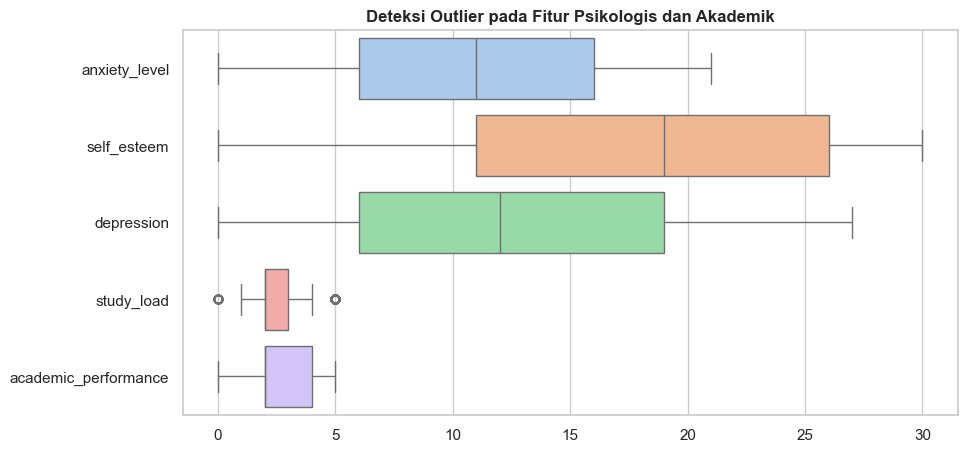

In [3]:
# ==========================================
# 1.3 VISUALISASI KUALITAS DATA & OUTLIER
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# ==========================================
# 1.3 INFORMASI DATASET & DISTRIBUSI (ANGKA)
# ==========================================

print("=== INFORMASI DATASET ===")
print(f"Jumlah Baris (Siswa) : {df.shape[0]}")
print(f"Jumlah Kolom (Fitur) : {df.shape[1]}")
print("Karakteristik Data   : Seluruh data telah dikonversi ke dalam format numerik")

print("\n=== DISTRIBUSI TINGKAT STRES (ANGKA) ===")
# Menghitung penyebaran data dan menyimpannya ke tabel
distribusi = df['stress_level'].value_counts().sort_index().to_frame().reset_index()
distribusi.columns = ['Tingkat Stres', 'Jumlah Siswa']
distribusi['Persentase (%)'] = round((distribusi['Jumlah Siswa'] / len(df)) * 100, 2)

# Mencetak angka dalam format tabel yang rapi
print(distribusi.to_string(index=False))

# Visualisasi Outlier (Boxplot)
fitur_numerik = ['anxiety_level', 'self_esteem', 'depression', 'study_load', 'academic_performance']
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[fitur_numerik], orient='h', palette='pastel')
plt.title('Deteksi Outlier pada Fitur Psikologis dan Akademik', fontsize=12, fontweight='bold')
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_10356\1572536776.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='stress_level', palette='viridis')


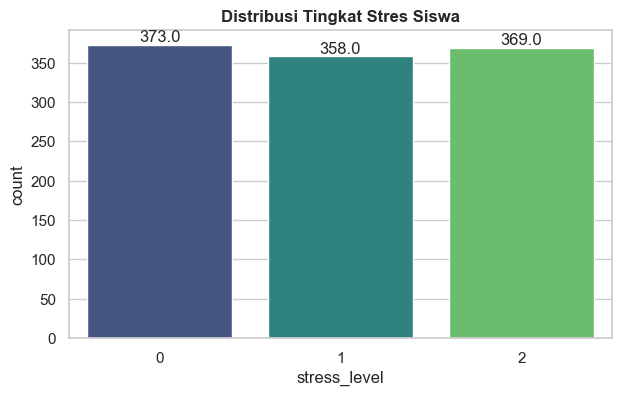

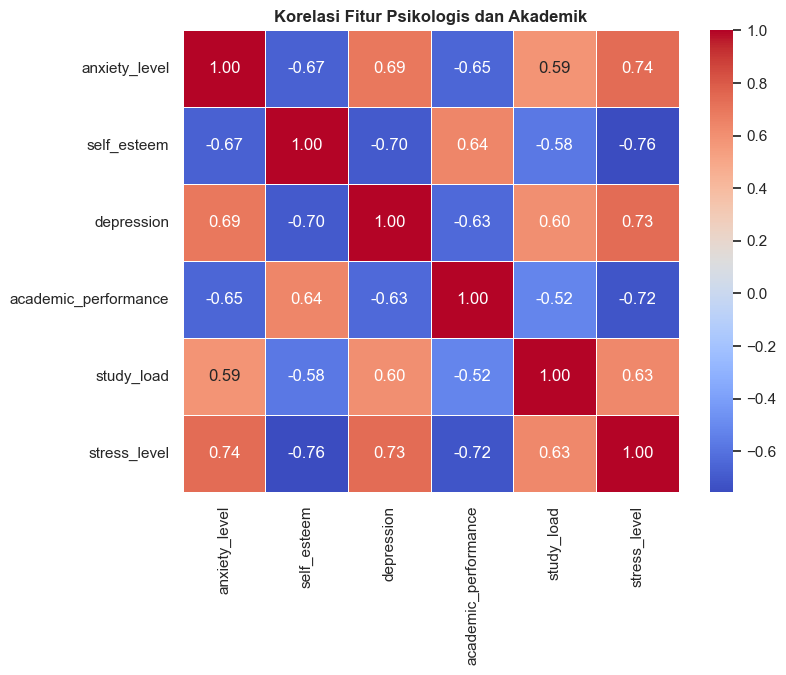

In [4]:
# ==========================================
# 1.4 EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================

# A. Distribusi Target Stres
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x='stress_level', palette='viridis')
plt.title('Distribusi Tingkat Stres Siswa', fontsize=12, fontweight='bold')
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom')
plt.show()

# B. Heatmap Korelasi
fitur_penting = ['anxiety_level', 'self_esteem', 'depression', 'academic_performance', 'study_load', 'stress_level']
plt.figure(figsize=(8, 6))
sns.heatmap(df[fitur_penting].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Korelasi Fitur Psikologis dan Akademik', fontsize=12, fontweight='bold')
plt.show()

In [5]:
# ==========================================
# 1.5 FEATURE ENGINEERING & PENENTUAN X - y
# ==========================================
import numpy as np

# Ekstraksi fitur (X) dan target (y)
X = df.drop('stress_level', axis=1).copy()
y = df['stress_level']

# Membuat fitur baru
X['mental_score'] = X['anxiety_level'] + X['depression']
X['academic_strain'] = (X['study_load'] + X['future_career_concerns']) / X['academic_performance']

# Mengubah nilai Infinity (tak terhingga) akibat pembagian dengan nol menjadi 0
X.replace([np.inf, -np.inf], 0, inplace=True)

print("Dimensi X (Fitur + Fitur Baru):", X.shape)
print("Dimensi y (Target):", y.shape)

Dimensi X (Fitur + Fitur Baru): (1100, 22)
Dimensi y (Target): (1100,)


In [6]:
# BINNING LOGIC
def binning_logic(X_subset):
    X_subset = pd.DataFrame(X_subset).copy()
    
    X_subset.iloc[:, 0] = pd.cut(X_subset.iloc[:, 0], bins=[-1, 4, 9, 14, 100], labels=False)
    X_subset.iloc[:, 1] = pd.cut(X_subset.iloc[:, 1], bins=[-1, 14, 25, 100], labels=False)
    X_subset.iloc[:, 2] = pd.cut(X_subset.iloc[:, 2], bins=[-1, 4, 9, 14, 19, 100], labels=False)
    
    return X_subset

In [7]:
# --- 3. PIPELINE SETUP ---
# 1. Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Preprocessor
preprocessor = ColumnTransformer([
    ('binning', FunctionTransformer(binning_logic), ['anxiety_level', 'self_esteem', 'depression']),
    ('scaling', StandardScaler(), [c for c in X.columns if c not in ['anxiety_level', 'self_esteem', 'depression']])
])

# Base Models
rf = RandomForestClassifier(random_state=42)
svc = SVC(probability=True, random_state=42)
knn = KNeighborsClassifier()
voting_sub = VotingClassifier(estimators=[('rf', rf), ('svc', svc), ('knn', knn)], voting='soft')

stacking_model = StackingClassifier(
    estimators=[('lr', LogisticRegression()), ('rf', rf), ('svc', svc), ('knn', knn), ('voting', voting_sub)],
    final_estimator=LogisticRegression(),
    cv=3
)

pipe = Pipeline([
    ('preprocess', preprocessor),
    ('feature_selection', RFE(
        estimator=RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ),
        n_features_to_select=12
    )),
    ('model', stacking_model)
])

In [8]:
# =========================================================
# 3.5 EKSPLORASI FEATURE SELECTION DENGAN RFE (Untuk Laporan TA)
# =========================================================
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier

# ---------------------------------------------------------
# KUNCI PENYELESAIAN ERROR: Mendefinisikan X_train_processed
# (Pastikan Sel 3 yang berisi 'preprocessor' sudah di-run sebelumnya)
# ---------------------------------------------------------
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# estimator untuk RFE
rfe_estimator = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# RFE
selector = RFE(
    estimator=rfe_estimator,
    n_features_to_select=12
)

# FIT & TRANSFORM TRAIN
X_train_selected = selector.fit_transform(
    X_train_processed,
    y_train
)

# TRANSFORM TEST
X_test_selected = selector.transform(
    X_test_processed
)

# =========================================================
# INFORMASI HASIL
# =========================================================
print("=== HASIL RECURSIVE FEATURE ELIMINATION (RFE) ===")
print("Shape sebelum feature selection:")
print(X_train_processed.shape)

print("\nShape setelah feature selection:")
print(X_train_selected.shape)

print("\nJumlah fitur awal:")
print(X_train_processed.shape[1])

print("\nJumlah fitur terpilih:")
print(selector.n_features_)

=== HASIL RECURSIVE FEATURE ELIMINATION (RFE) ===
Shape sebelum feature selection:
(880, 22)

Shape setelah feature selection:
(880, 12)

Jumlah fitur awal:
22

Jumlah fitur terpilih:
12


In [9]:
# --- 4. TRAINING & TUNING ---
# Baseline (Sebelum Tuning)
pipe.fit(X_train, y_train)
acc_baseline = accuracy_score(y_test, pipe.predict(X_test))

# Tuning 
param_dist = {'model__rf__n_estimators': [100, 200], 'model__final_estimator__C': [0.1, 1.0, 10.0]}
search = search = RandomizedSearchCV(
    pipe,
    param_distributions=param_dist,
    n_iter=10,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1,
    random_state=42,
    verbose=2
)
search.fit(X_train, y_train)

best_model = search.best_estimator_


y_pred = best_model.predict(X_test)
acc_tuned = accuracy_score(y_test, y_pred)

c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_search.py:307: UserWarning: The total space of parameters 6 is smaller than n_iter=10. Running 6 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Fitting 5 folds for each of 6 candidates, totalling 30 fits


In [10]:
# ==========================================
# 4. HYBRID MODEL ARCHITECTURE & PIPELINE UPDATE
# ==========================================
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import RFE

# Base Learners Individual 
lr = LogisticRegression(max_iter=1000, random_state=42)
ridge = RidgeClassifier(random_state=42)
svc = SVC(probability=True, random_state=42)

# Sub-Ensemble: Voting 
rf_vote = RandomForestClassifier(random_state=42)
knn_vote = KNeighborsClassifier()
et_vote = ExtraTreesClassifier(random_state=42) 

voting_sub = VotingClassifier(
    estimators=[('rf_v', rf_vote), ('knn_v', knn_vote), ('et_v', et_vote)],
    voting='soft'
)

# Stacking
stacking_model = StackingClassifier(
    estimators=[
        ('lr', lr), 
        ('ridge', ridge), 
        ('svc', svc), 
        ('voting_tree', voting_sub) 
    ],
    final_estimator=XGBClassifier(random_state=42, eval_metric='mlogloss'),
    cv=5
)

pipe = Pipeline([
    ('preprocess', preprocessor),
    ('feature_selection', RFE(estimator=RandomForestClassifier(random_state=42), n_features_to_select=12)),
    ('model', stacking_model) 
])

print("Arsitektur berhasil dirakit dan dimasukkan ke dalam Pipeline!")

Arsitektur berhasil dirakit dan dimasukkan ke dalam Pipeline!


In [11]:
# =========================================================
# 5. TRAINING ULANG PIPELINE SECARA BERSIH
# =========================================================
import time
import joblib

print("Melatih ulang model dari awal agar memori sinkron...")
start_time = time.time()

# 1. Melatih ulang pipeline (Otomatis: Preprocess -> RFE -> Stacking)
# Gunakan pipe.fit (jika tidak pakai tuning) atau random_search.fit (jika pakai tuning)
pipe.fit(X_train, y_train)

# Kita simpan model yang benar-benar fresh ini ke variabel best_model
best_model = pipe 

end_time = time.time()
print(f"Training selesai dalam {end_time - start_time:.2f} detik!")

# 2. Menyimpan model baru ke file .pkl (Menimpa yang lama)
joblib.dump(best_model, 'model_stress_final.pkl')
print("Model baru berhasil disimpan ke 'model_stress_final.pkl'")


# =========================================================
# 6. PREDIKSI MODEL FINAL
# =========================================================
print("\nMelakukan Prediksi...")

# KUNCI: Gunakan X_test (data mentah), biarkan pipeline yang memotongnya jadi 12
y_pred = best_model.predict(X_test)

# Menghitung probabilitas (jika model mendukung)
if hasattr(best_model, "predict_proba"):
    y_prob = best_model.predict_proba(X_test)
else:
    y_prob = None

print("Prediksi Berhasil Tanpa Error!")

# (Lanjutkan dengan kode evaluasi metrik atau visualisasi Anda setelah ini...)

Melatih ulang model dari awal agar memori sinkron...
Training selesai dalam 4.84 detik!
Model baru berhasil disimpan ke 'model_stress_final.pkl'

Melakukan Prediksi...
Prediksi Berhasil Tanpa Error!


ROC AUC Score: 0.9860


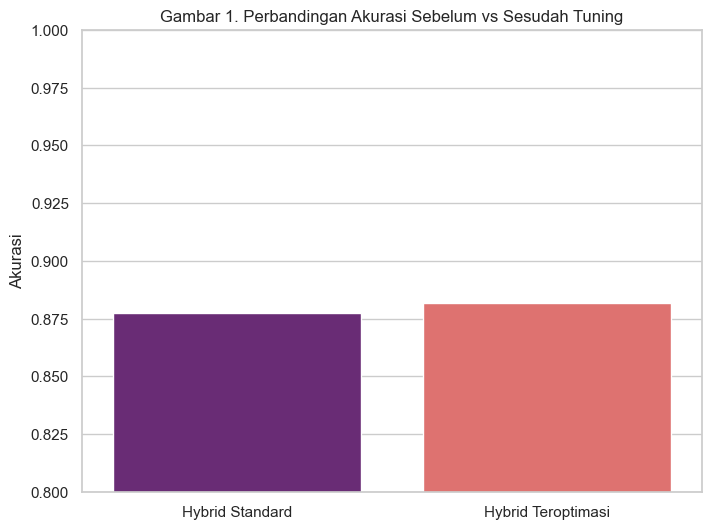

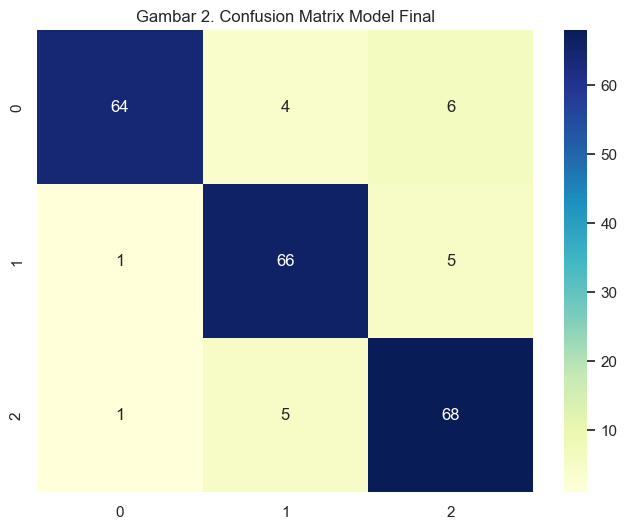

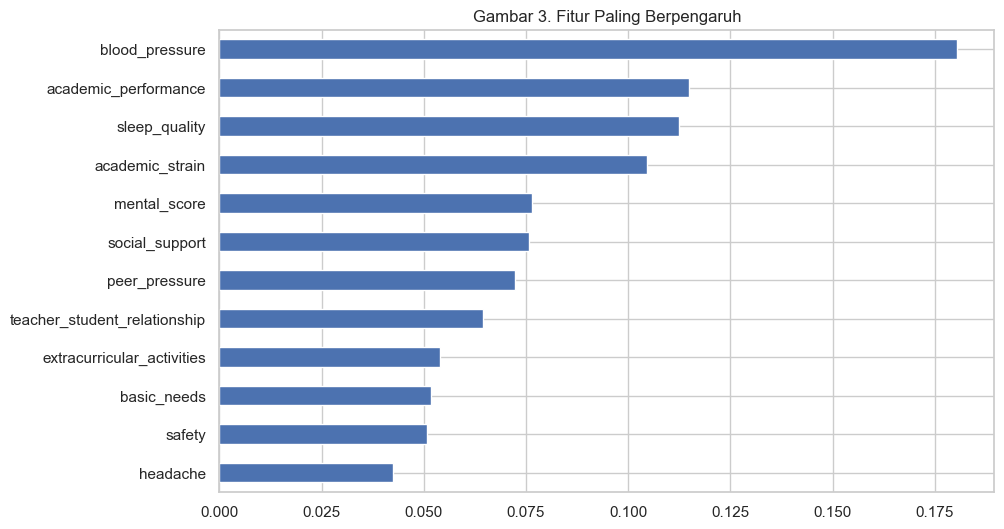

In [12]:
# --- 5. VISUALISASI (GAMBAR & PERBANDINGAN) ---
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize
import numpy as np

# A. Grafik Perbandingan Akurasi (Feature Perbandingan)
plt.figure(figsize=(8, 6))
sns.barplot(
    x=['Hybrid Standard', 'Hybrid Teroptimasi'], 
    y=[acc_baseline, acc_tuned], 
    hue=['Hybrid Standard', 'Hybrid Teroptimasi'], 
    palette='magma',
    legend=False                                   
)
plt.title('Gambar 1. Perbandingan Akurasi Sebelum vs Sesudah Tuning')
plt.ylabel('Akurasi')
plt.ylim(0.8, 1.0)
plt.savefig('hasil_perbandingan.png')

# Mengambil probabilitas prediksi
y_prob = best_model.predict_proba(X_test)

# Karena target Anda multiclass (Anxious, Calm, Tense, Relaxed), kita ubah menjadi biner
classes = np.unique(y)
y_test_bin = label_binarize(y_test, classes=classes)

# Menghitung nilai AUC
auc_score = roc_auc_score(y_test_bin, y_prob, multi_class='ovr')
print(f"ROC AUC Score: {auc_score:.4f}")

# B. Confusion Matrix (Gambar Evaluasi)
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='YlGnBu')
plt.title('Gambar 2. Confusion Matrix Model Final')
plt.savefig('hasil_confusion_matrix.png')

# C. Feature Importance (Gambar Seleksi Fitur)
importances = best_model.named_steps['feature_selection'].estimator_.feature_importances_
plt.figure(figsize=(10, 6))

pd.Series(importances, index=X.columns[best_model.named_steps['feature_selection'].get_support()]).sort_values().plot(kind='barh')

plt.title('Gambar 3. Fitur Paling Berpengaruh')
plt.savefig('hasil_feature_importance.png')
plt.show()

Mengekstrak model yang sudah dilatih dari dalam Pipeline...


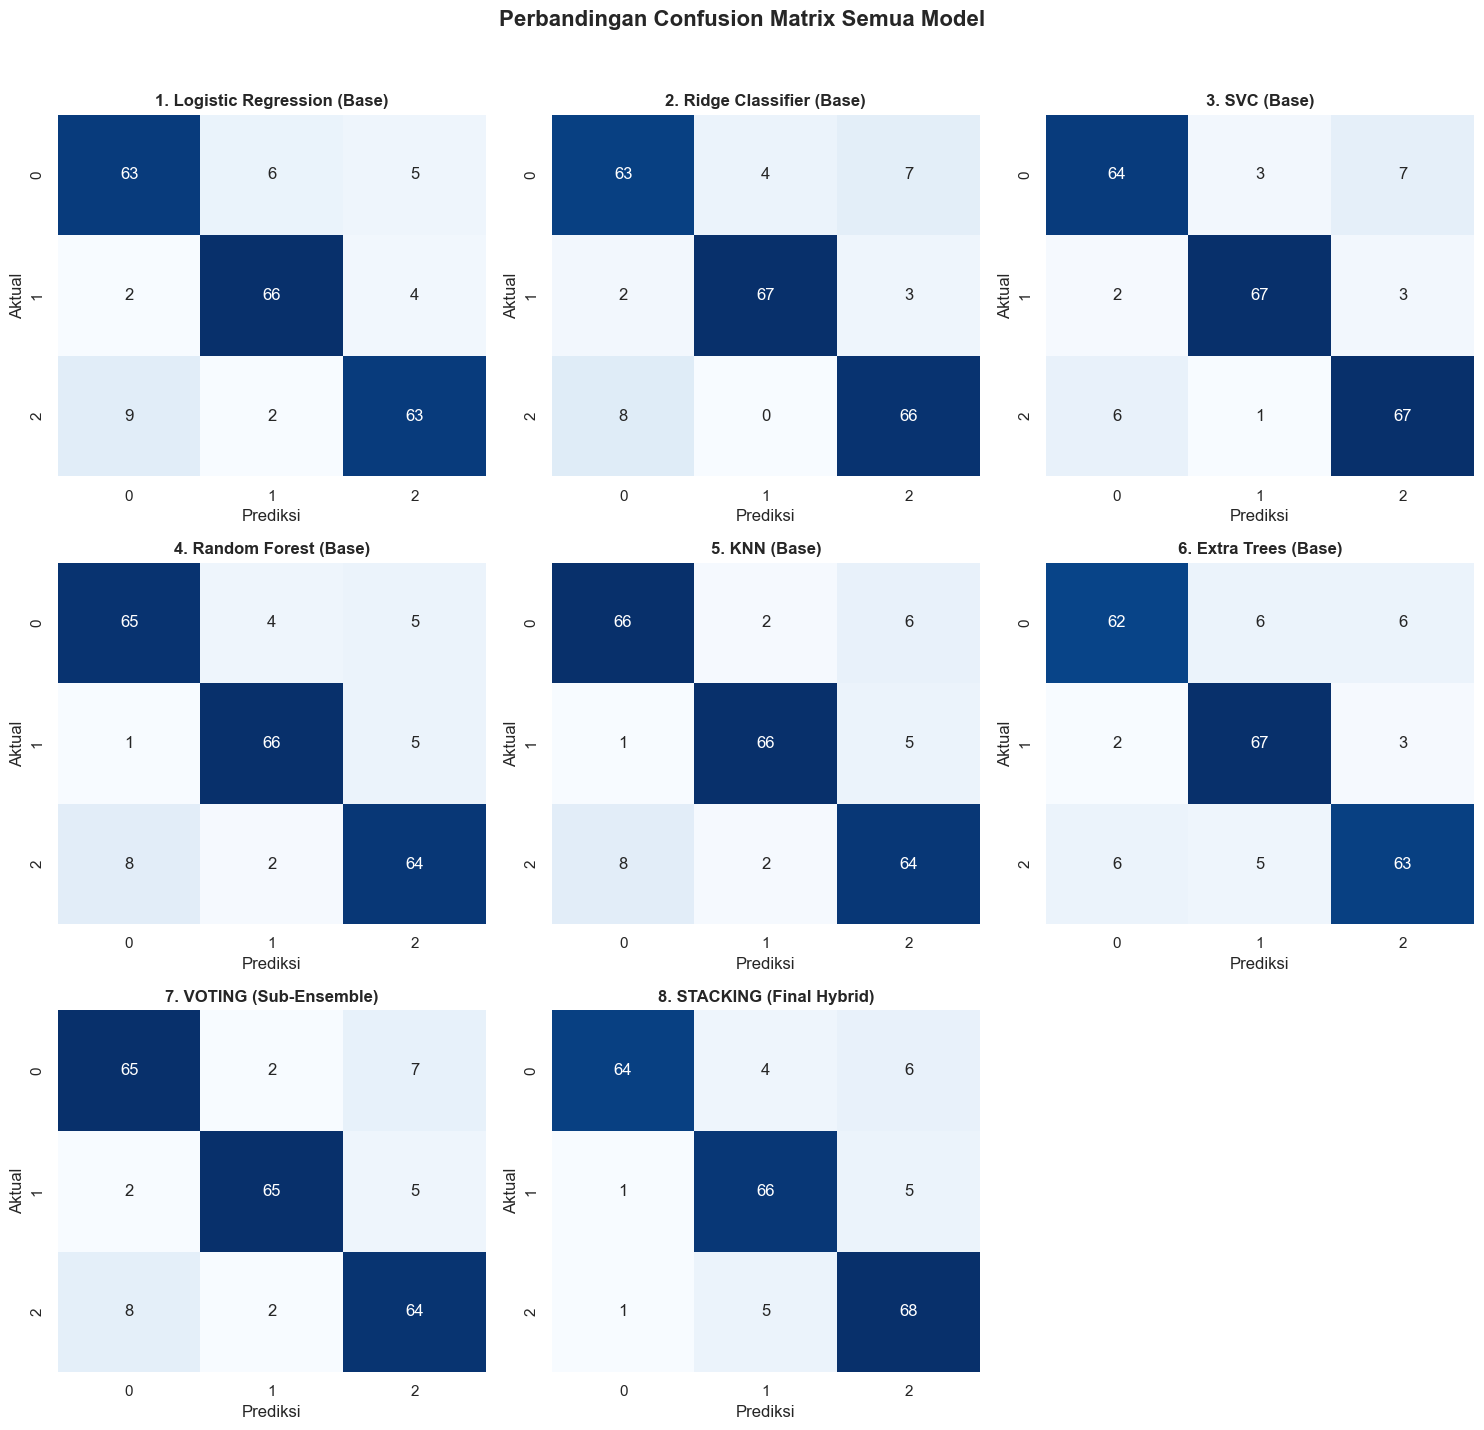


   TABEL HASIL KOMPARASI SELURUH ALGORITMA
                   Nama Model Akurasi F1-Score
1. Logistic Regression (Base)  87.27%   87.25%
   2. Ridge Classifier (Base)  89.09%   89.10%
                3. SVC (Base)  90.00%   90.01%
      4. Random Forest (Base)  88.64%   88.64%
                5. KNN (Base)  89.09%   89.12%
        6. Extra Trees (Base)  87.27%   87.23%
     7. VOTING (Sub-Ensemble)  88.18%   88.22%
   8. STACKING (Final Hybrid)  90.00%   90.04%


In [13]:
# =========================================================
# 6. EVALUASI BERSIH: EKSTRAKSI SEMUA MODEL DARI PIPELINE
# =========================================================
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

print("Mengekstrak model yang sudah dilatih dari dalam Pipeline...")

# 1. Pastikan kita punya variabel best_model (hasil dari pipe.fit)
best_model = pipe  # Gunakan variabel pipe Anda yang sudah di-fit

# 2. KUNCI PENTING: Siapkan data X_test yang dipotong (12 fitur) 
# Model dasar di dalam pipeline hanya mengenali 12 fitur, jadi kita harus siapkan datanya
X_test_prep = best_model.named_steps['preprocess'].transform(X_test)
X_test_12_fitur = best_model.named_steps['feature_selection'].transform(X_test_prep)

# 3. Ekstrak Sang Manajer (Stacking Classifier)
stacking_model = best_model.named_steps['model']
voting_model = stacking_model.named_estimators_['voting_tree']

# 4. Kumpulkan semua model ke dalam satu dictionary agar rapi
models_dict = {
    '1. Logistic Regression (Base)': stacking_model.named_estimators_['lr'],
    '2. Ridge Classifier (Base)': stacking_model.named_estimators_['ridge'],
    '3. SVC (Base)': stacking_model.named_estimators_['svc'],
    '4. Random Forest (Base)': voting_model.named_estimators_['rf_v'],
    '5. KNN (Base)': voting_model.named_estimators_['knn_v'],
    '6. Extra Trees (Base)': voting_model.named_estimators_['et_v'],
    '7. VOTING (Sub-Ensemble)': voting_model,
    '8. STACKING (Final Hybrid)': stacking_model
}

# 5. Looping untuk Evaluasi & Visualisasi
results = []
fig, axes = plt.subplots(3, 3, figsize=(15, 14))
fig.suptitle('Perbandingan Confusion Matrix Semua Model', fontsize=16, fontweight='bold', y=1.02)
axes = axes.flatten()

for idx, (nama_model, model_terlatih) in enumerate(models_dict.items()):
    # Gunakan data yang berisi 12 fitur untuk model hasil ekstraksi
    y_pred = model_terlatih.predict(X_test_12_fitur)
    
    # Hitung Metrik
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    results.append({'Nama Model': nama_model, 'Akurasi': acc, 'F1-Score': f1})
    
    # Gambar Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(nama_model, fontweight='bold')
    axes[idx].set_xlabel('Prediksi')
    axes[idx].set_ylabel('Aktual')

# Hapus kotak kosong ke-9
fig.delaxes(axes[8])
plt.tight_layout()
plt.show()

# 6. Tampilkan Tabel Ringkasan
print("\n" + "="*50)
print("   TABEL HASIL KOMPARASI SELURUH ALGORITMA")
print("="*50)
df_results = pd.DataFrame(results)
df_results['Akurasi'] = df_results['Akurasi'].apply(lambda x: f"{x*100:.2f}%")
df_results['F1-Score'] = df_results['F1-Score'].apply(lambda x: f"{x*100:.2f}%")
print(df_results.to_string(index=False))
print("="*50)

In [14]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize
import numpy as np
import joblib

# =========================================================
# PREDIKSI MODEL FINAL
# =========================================================
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)

# =========================================================
# METRIK
# =========================================================
acc_tuned = accuracy_score(
    y_test,
    y_pred
)

f1_tuned = f1_score(
    y_test,
    y_pred,
    average='weighted'
)

# =========================================================
# ROC AUC
# =========================================================
classes = np.unique(y)
y_test_bin = label_binarize(
    y_test,
    classes=classes
)

auc_score = roc_auc_score(
    y_test_bin,
    y_prob,
    multi_class='ovr'
)

# =========================================================
# SAVE MODEL
# =========================================================
joblib.dump(
    best_model,
    'model_stress_final.pkl'
)

# =========================================================
# HASIL AKHIR
# =========================================================
print("=" * 50)
print(" HASIL EVALUASI MODEL FINAL ")
print("=" * 50)
print(f"Akurasi Akhir : {acc_tuned:.4f} ({acc_tuned*100:.2f}%)")
print(f"F1-Score      : {f1_tuned:.4f} ({f1_tuned*100:.2f}%)")
print(f"ROC-AUC Score : {auc_score:.4f} ({auc_score*100:.2f}%)")
print("=" * 50)
print("Model berhasil disimpan:")
print("model_stress_final.pkl")

 HASIL EVALUASI MODEL FINAL 
Akurasi Akhir : 0.9000 (90.00%)
F1-Score      : 0.9004 (90.04%)
ROC-AUC Score : 0.9860 (98.60%)
Model berhasil disimpan:
model_stress_final.pkl


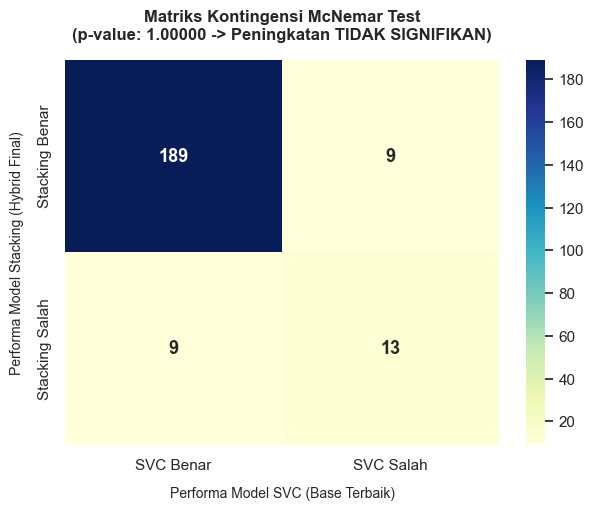

Nilai p-value: 1.00000
Kesimpulan   : Perbedaan performa TIDAK SIGNIFIKAN secara statistik.


In [15]:
from statsmodels.stats.contingency_tables import mcnemar

# 1. Ambil prediksi dari Stacking (Hybrid) dan SVC (Base Terbaik)
y_pred_stacking = best_model.predict(X_test)
y_pred_svc = stacking_model.named_estimators_["svc"].predict(X_test_12_fitur)

# 2. Susun Kontingensi Matriks secara Manual
# [0,0]: Kedua model benar
# [0,1]: SVC benar, Stacking salah
# [1,0]: SVC salah, Stacking benar
# [1,1]: Kedua model salah
a = np.sum((y_pred_svc == y_test) & (y_pred_stacking == y_test))
b = np.sum((y_pred_svc == y_test) & (y_pred_stacking != y_test))
c = np.sum((y_pred_svc != y_test) & (y_pred_stacking == y_test))
d = np.sum((y_pred_svc != y_test) & (y_pred_stacking != y_test))

contingency_table = np.array([[a, b], [c, d]])

# 3. Hitung McNemar Test untuk mendapatkan p-value
result = mcnemar(contingency_table, exact=True)
p_value = result.pvalue

# 4. Membuat Visualisasi Gambar Tabel Kontingensi McNemar
plt.figure(figsize=(7, 5))

# Definisikan label sumbu berdasarkan performa kebenaran prediksi
labels_x = ["SVC Benar", "SVC Salah"]
labels_y = ["Stacking Benar", "Stacking Salah"]

# Tampilkan Heatmap
sns.heatmap(
    contingency_table,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    cbar=True,
    xticklabels=labels_x,
    yticklabels=labels_y,
    annot_kws={"size": 13, "weight": "bold"},
)

# Berikan judul dinamis sesuai hasil signifikansi statistik
status_signifikansi = "SIGNIFIKAN" if p_value < 0.05 else "TIDAK SIGNIFIKAN"
plt.title(
    f"Matriks Kontingensi McNemar Test\n(p-value: {p_value:.5f} -> Peningkatan {status_signifikansi})",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Performa Model SVC (Base Terbaik)", fontsize=10, labelpad=10)
plt.ylabel("Performa Model Stacking (Hybrid Final)", fontsize=10, labelpad=10)

# Otomatis simpan grafik menjadi gambar resolusi tinggi untuk disisipkan ke Word
plt.savefig("hasil_uji_mcnemar.png", bbox_inches="tight", dpi=300)
plt.show()

# Cetak kesimpulan tekstual di bawah gambar sebagai cadangan catatan
print(f"Nilai p-value: {p_value:.5f}")
if p_value < 0.05:
    print(
        "Kesimpulan   : Perbedaan performa SIGNIFIKAN secara statistik. Model Hybrid Stacking terbukti memberikan peningkatan nyata."
    )
else:
    print(
        "Kesimpulan   : Perbedaan performa TIDAK SIGNIFIKAN secara statistik."
    )

In [16]:
from sklearn.metrics import accuracy_score

# Prediksi training
y_train_pred = best_model.predict(X_train)

# Accuracy train
train_acc = accuracy_score(y_train, y_train_pred)

# Accuracy test
test_acc = accuracy_score(y_test, y_pred)

print(f"Training Accuracy : {train_acc:.4f}")
print(f"Testing Accuracy  : {test_acc:.4f}")

# Gap overfitting
gap = train_acc - test_acc
print(f"Overfitting Gap   : {gap:.4f}")

Training Accuracy : 0.9386
Testing Accuracy  : 0.9000
Overfitting Gap   : 0.0386


In [17]:
import pandas as pd
import numpy as np
import joblib

print("="*60)
# Penyelarasan Penuh dengan Aturan Data Input Web Form & Server Flask Backend
print("SIMULASI PENGECEKAN INTERAKTIF SINKRON WEB APP (14 FITUR UTAMA)")
print("="*60)
print("Silakan isi data nilai indikator sesuai pengisian formulir siswa:")

try:
    # 1. Input Manual Fitur Klinis & Indikator Akademik/Sosial (Sesuai Form Web)
    gad7_score = float(input("- Masukkan Total Skor GAD-7 Kecemasan (Skala 0-21): "))
    phq9_score = float(input("- Masukkan Total Skor PHQ-9 Depresi (Skala 0-27): "))
    academic_performance = float(input("  * Performa Akademik (0-5): "))
    study_load = float(input("  * Beban Tugas & Jam Belajar (0-5): "))
    future_career_concerns = float(input("  * Kekhawatiran Karir Masa Depan (0-5): "))
    teacher_student_relationship = float(input("  * Hubungan dengan Guru (0-5): "))
    headache = float(input("  * Intensitas Sakit Kepala (0-5): "))
    sleep_quality = float(input("  * Kualitas Tidur Malam (0-5): "))
    safety = float(input("  * Rasa Aman Lingkungan Sekitar (0-5): "))
    basic_needs = float(input("  * Pemenuhan Kebutuhan Dasar (0-5): "))
    social_support = float(input("  * Dukungan Sosial  (0-5): "))
    peer_pressure = float(input("  * Tekanan dari Teman Sebaya (0-5): "))
    extracurricular_activities = float(input("  * Keaktifan Ekstrakurikuler (0-5): "))
    blood_pressure = float(input("  * Tekanan Darah (1: Rendah, 2: Normal, 3: Tinggi): "))

    # =========================================================================
    # 2. FITUR OTOMATIS / DEFAULT (Fitur yang disembunyikan/tidak di-input di web)
    # =========================================================================
    self_esteem = 15.0               # Nilai tengah netral skala Rosenberg (0-30)
    mental_health_history = 0.0      # Default: Tidak ada riwayat
    living_conditions = 3.0          # Default: Cukup layak
    bullying = 0.0                   # Default: Tidak mengalami perundungan
    breathing_problem = 0.0          # Default: Normal
    noise_level = 2.0                # Default: Sedang

    # =========================================================================
    # 3. AUTO-FEATURE ENGINEERING (Kalkulasi Matematis Otomatis Latar Belakang)
    # =========================================================================
    perf_safe = academic_performance if academic_performance > 0 else 1e-5
    
    calc_mental_score = gad7_score + phq9_score
    calc_academic_strain = (study_load + future_career_concerns) / perf_safe

    # 4. Susun ke dalam kamus data tunggal
    data_input = {
        'anxiety_level': [gad7_score],
        'self_esteem': [self_esteem],
        'depression': [phq9_score],
        'mental_health_history': [mental_health_history],
        'headache': [headache],
        'blood_pressure': [blood_pressure],
        'sleep_quality': [sleep_quality],
        'breathing_problem': [breathing_problem],
        'noise_level': [noise_level],
        'living_conditions': [living_conditions],
        'safety': [safety],
        'basic_needs': [basic_needs],
        'academic_performance': [academic_performance],
        'study_load': [study_load],
        'teacher_student_relationship': [teacher_student_relationship],
        'future_career_concerns': [future_career_concerns],
        'social_support': [social_support],
        'peer_pressure': [peer_pressure],
        'extracurricular_activities': [extracurricular_activities],
        'bullying': [bullying],
        'mental_score': [calc_mental_score],
        'academic_strain': [calc_academic_strain]
    }

    # 5. Transformasi ke Dataframe Pandas & Amankan Urutan Kolom Sesuai Fit Pipeline Asli
    df_simulasi = pd.DataFrame(data_input)
    kolom_transformer_order = [
        'anxiety_level', 'self_esteem', 'depression',
        'mental_health_history', 'headache', 'blood_pressure', 'sleep_quality',
        'breathing_problem', 'noise_level', 'living_conditions', 'safety',
        'basic_needs', 'academic_performance', 'study_load',
        'teacher_student_relationship', 'future_career_concerns', 'social_support',
        'peer_pressure', 'extracurricular_activities', 'bullying',
        'mental_score', 'academic_strain'
    ]
    df_simulasi = df_simulasi[kolom_transformer_order]

    # 6. Pemuatan Model Terlatih (.pkl)
    model_path = 'model_stress_final.pkl'
    loaded_pipeline = joblib.load(model_path)
    
    # Proteksi Version Mismatch otomatis untuk parameter scikit-learn runtime
    def patch_estimator(est):
        if est is None: return
        if not hasattr(est, 'monotonic_cst') and est.__class__.__name__ in ['DecisionTreeClassifier', 'DecisionTreeRegressor']:
            est.monotonic_cst = None
        if hasattr(est, 'estimators_'):
            try:
                for sub_est in est.estimators_: patch_estimator(sub_est)
            except: pass
        if hasattr(est, 'named_estimators_'):
            for sub_est in est.named_estimators_.values(): patch_estimator(sub_est)
        if hasattr(est, 'final_estimator_'): patch_estimator(est.final_estimator_)

    if hasattr(loaded_pipeline, 'steps'):
        for name, step in loaded_pipeline.steps: patch_estimator(step)
    else:
        patch_estimator(loaded_pipeline)

    # 7. Eksekusi Prediksi Akhir Model Hibrida Stacking
    hasil_prediksi = loaded_pipeline.predict(df_simulasi)[0]
    
    # Pemetaan Label Output Teks Resmi BK
    mapping_label = {0: "RENDAH", 1: "SEDANG", 2: "TINGGI"}
    
    print("\n" + "="*60)
    print(f" HASIL SIMULASI PREDIKSI TINGKAT STRES AI : {mapping_label.get(hasil_prediksi, 'UNKNOWN')}")
    
    if hasattr(loaded_pipeline, "predict_proba"):
        probabilitas = loaded_pipeline.predict_proba(df_simulasi)[0]
        prob_formatted = [f"{p*100:.2f}%" for p in probabilitas]
        print(f" Probabilitas Keyakinan [Rendah, Sedang, Tinggi]: {prob_formatted}")
    print("="*60)

except ValueError:
    print("\n FORMAT INPUT SALAH: Pastikan Anda memasukkan angka numerik yang valid!")
except Exception as e:
    print(f"\n TERJADI ERROR PADA PROSES PREDIKSI: {str(e)}")

SIMULASI PENGECEKAN INTERAKTIF SINKRON WEB APP (14 FITUR UTAMA)
Silakan isi data nilai indikator sesuai pengisian formulir siswa:

 FORMAT INPUT SALAH: Pastikan Anda memasukkan angka numerik yang valid!
